# Bayesian Classification
Henry Arnold, Cole Clodgo, Bao Lam, Nguyen Nguyen, Ryan Vo

In this project we compute Bayesian classifications for the MNIST data set. This data set contains images of handdrawn digits. We choose the digits 7 and 9 for classification. We try two different likelihood functions, a normal distribution and a Bernoulli distribution. We first compute the classifications by hand, and then use the sklearn package to also compute the classifications.

In [153]:
# module imports
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

## Getting the Data
We get the mnist dataset from keras already split into training and testing data. X_train and X_test contain the training and testing images as numpy arrays of pixels. Y_train and Y_test contain the digit labels for each image in X_train and X_test. We filter down to just two digits for our binary classification, choosing 7 and 9. To get the image data into a more workable form, we flatten them from 28x28 2D arrays down to a 1D array of 784 pixels, and convert the pixel values to floats for later calculations. The images remain grayscale rather than being converted to black and white.

In [47]:
# get the data
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

# Choose two digits
digit1 = 7
digit2 = 9

# Keeping only the selected digits
train_mask = (Y_train == digit1) | (Y_train == digit2)
test_mask = (Y_test == digit1) | (Y_test == digit2)

X_train = X_train[train_mask]
Y_train = Y_train[train_mask]

X_test = X_test[test_mask]
Y_test = Y_test[test_mask]

# Flattening images from 28x28 to 784 pixels
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

# Convert to float for later calculations
X_train = X_train.astype(float)
X_test = X_test.astype(float)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)


Training samples: (12214, 784)
Testing samples: (2037, 784)


## Assumption: Normal Distribution

### I. Hand-Coded Normal Distribution

#### 1. Model Training

##### a) Mean, Variance, and Standard Deviation Calculation

In [52]:
# Mean
def mean(data_set):
    mean_array = np.mean(data_set, axis=0)
    return mean_array


# Standard deviation
def standard_deviation(data_set):
    std_array = np.std(data_set, axis=0)
    return std_array

# Smooth variance to keep them from being zero in denominator
def smooth_variance(standard_deviation):
    variance = standard_deviation**2
    constant = (10**-9) * np.max(variance)
    return variance + constant


In [53]:
# Execution

## Separate training images by digit
X_train_7 = X_train[Y_train == 7]
X_train_9 = X_train[Y_train == 9]

## Calculate mean arrays
mean_7 = mean(X_train_7)
mean_9 = mean(X_train_9)

## Calculate standard deviation arrays
sd_7 = standard_deviation(X_train_7)
sd_9 = standard_deviation(X_train_9)

## Calculate the smooth variance arrays
variance_7 = smooth_variance(sd_7)
variance_9 = smooth_variance(sd_9)

##### b) Prior Calculation

In [55]:
# Prior function
def prior(label_set, chosen_class, other_class):
    chosen_count = np.sum(label_set == chosen_class)
    other_count = np.sum(label_set == other_class)
    return chosen_count / (chosen_count + other_count)

In [56]:
# Execution

## Calculate prior for 7
prior_7 = prior(Y_train, 7, 9)

## Calculate prior for 9
prior_9 = prior(Y_train, 9, 7)

##### c) Gaussian Likelihood

In [58]:
# Likelihood function
# Taking the log of the Gaussian likelihood function give us the formula for log likelihood
# Use that formula to derive the function

def log_likelihood(data_set, mean_array, variance_array):
    log_density = (-0.5 * np.log(2 * np.pi * variance_array) - ((data_set - mean_array)**2 / (2 * variance_array)))
    log_likelihood = np.sum(log_density, axis=1)

    return log_likelihood

In [59]:
# Execution
log_likelihood_7 = log_likelihood(X_test, mean_7, variance_7)
log_likelihood_9 = log_likelihood(X_test, mean_9, variance_9)


##### d) Discriminant Function

In [61]:
# Calculating gi(x)

g_7 = log_likelihood_7 + np.log(prior_7)
g_9 = log_likelihood_9 + np.log(prior_9)

#### 2. Model Testing

In [63]:
# Predict 7 if g_7 larger than g_9
Y_pred = np.where(g_7 > g_9, 7, 9)

#### 3. Model Evaluating

In [65]:
# Accuracy
accuracy = accuracy_score(Y_test, Y_pred)

# F1 score (digit 9 as positive class)
f1 = f1_score(Y_test, Y_pred, pos_label=9)

# Confusion matrix
cm = confusion_matrix(Y_test, Y_pred, labels=[7, 9])

print("Accuracy:", accuracy)
print("F1 score:", f1)
print("Confusion matrix:\n", cm)

Accuracy: 0.6401570937653411
F1 score: 0.7294204503506829
Confusion matrix:
 [[316 712]
 [ 21 988]]


When assuming a normally distributed likelihood function and calculating the Bayesian classifications by hand, we achieve an accuracy of 0.64 and an F1 score of 0.73.

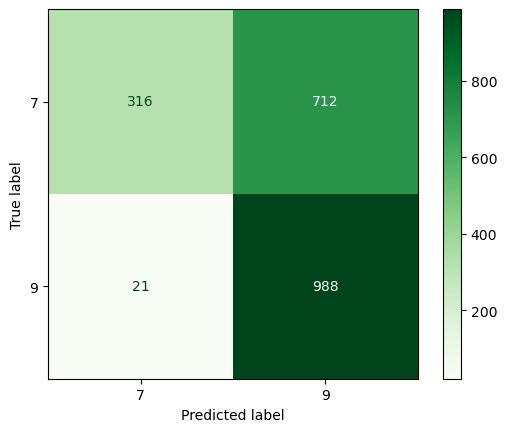

In [67]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[7, 9]
).plot(cmap="Greens")

plt.show()

### II. Scikit-Learn Gaussian Distribution

#### 1. Fit the Model

In [70]:
# Initialize model
clf = GaussianNB()

# Fit the model using training data
clf.fit(X_train, Y_train)

# Predict test data
Y_pred_sklearn = clf.predict(X_test)

#### 2. Model Evaluation

In [72]:
# Accuracy
accuracy_sklearn = accuracy_score(Y_test, Y_pred_sklearn)

# F1 score (digit 9 as positive class)
f1_sklearn = f1_score(Y_test, Y_pred_sklearn, pos_label=9)

# Confusion matrix
cm_sklearn = confusion_matrix(Y_test, Y_pred_sklearn, labels=[7, 9])

print("Accuracy:", accuracy_sklearn)
print("F1 Score:", f1_sklearn)
print("Confusion Matrix:\n", cm_sklearn)

Accuracy: 0.6406480117820325
F1 Score: 0.7296898079763663
Confusion Matrix:
 [[317 711]
 [ 21 988]]


When assuming a normally distributed likelihood function and using the sklearn GaussianNB classifier to compute the Bayesian classifications, we achieve an accuracy of 0.64 and an F1 score of 0.73.

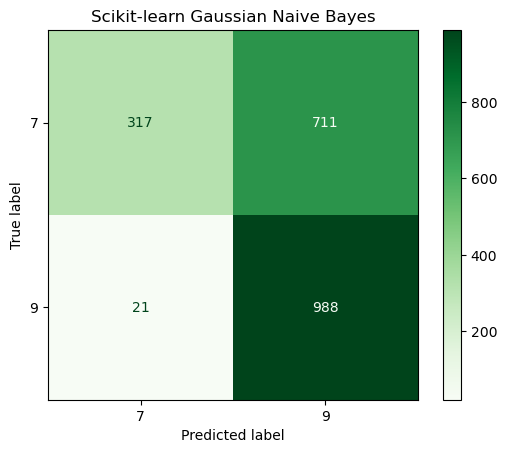

In [74]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_sklearn,
    display_labels=[7, 9]
).plot(cmap="Greens")

plt.title("Scikit-learn Gaussian Naive Bayes")
plt.show()

### III. Normal Likelihood Analysis and Hypothesis
We compute the confusion matrices made by doing Bayesian classification where we assume the likelihood function is normally distributed by hand, as well as by using the sklearn built-in GaussianNB classifier. The two confusion matrices are almost identical beside one 7 gets falsely classified as 9 by the hand-coded model. The slight difference may be due to the way variance smoothing is calculated.

Both models have an accuracy of about 0.64, meaning they correctly identify about 64% of the test images. They also both have an F1 score of about 0.73 for digit 9. The confusion matrix points to the fact that the Gaussian-distribution models do a poor job at predicting 7s. They almost predict all 9s correctly (recall = 0.98), but about 69% of 7s got falsely classified as 9s. We can conclude the Gaussian-distribution Bayesian model favors predicting 9s against 7s (they predict 9s for 83.4% of all images).

Now, to explore why this is the case, there are three hypothesis that need to be verified:

1. The Gaussian distribution may not adequately represent MNIST pixel intensities: verify by trying to graph the distribution of pixel data for the train set or fitting the train set using a different distribution assumption (Bernouli).
2. The training data may contain more 9s than 7s, which make the prior of 9s larger, making the models tend to favor 9's predictions: verify by examining the proportion of each digit in the train set (meaning, looking at priors).
3. Some handwritten 7s may be difficult to distinguish from 9s, which could confuse the model: verify by selecting some 7's images to examine.

### IV. Hypothesis Verification

#### 1. Normal Distribution is bad Assumption

There are two ways that can test this hypothesis: (1) Plot the distribution of one or many particular pixels of 7 and 9 digits to examine the distribution of them and (2) Fit another model using a different distribution (Bernoulli?) to see if it performs better. Let's do (1) here:

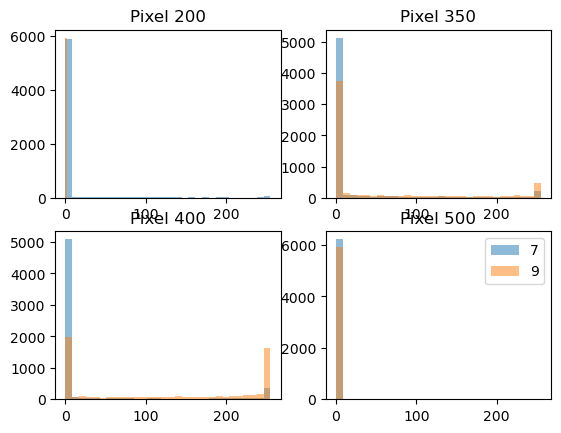

In [79]:
pixels = [200, 350, 400, 500]

fig, axes = plt.subplots(2, 2)

for ax, pixel in zip(axes.flat, pixels):
    ax.hist(X_train_7[:, pixel], bins=30, alpha=0.5, label="7")
    ax.hist(X_train_9[:, pixel], bins=30, alpha=0.5, label="9")
    ax.set_title(f"Pixel {pixel}")

plt.legend()
plt.show()

The plots illustrate the distribution of several particular pixels (200, 350, 400, and 500) of digit 7s and 9s.

They provide strong preliminary evidence that we cannot reject the hypothesis (it might be true!). The distribution of the pixels resemble anything but a bell-shaped graph, with large concentration of observations at zero.

The results support the idea that the Gaussian likelihood assumption is a poor fit for at least some MNIST pixel features. We cannot say that it is the primary cause just yet, because we still have a 64% accuracy.

#### 2. Train set 7/9 split is skewed

In [82]:
# previously calculated priors
print(f"Prior for digit 7: {prior_7:.4f} ({prior_7:.2%})")
print(f"Prior for digit 9: {prior_9:.4f} ({prior_9:.2%})")

Prior for digit 7: 0.5129 (51.29%)
Prior for digit 9: 0.4871 (48.71%)


This result rejects the hypothesis. There is only a 3% different in the number of 7s and 9s. This even goes against our hypothesis, there is more 7s than 9s, so if the split of 7/9 in train set really impacted our model, the model should have favored predicting 7s more instead of vice versa.

So, this is not why our model generated poor results.

#### 3. Bad hand-writing for 7s

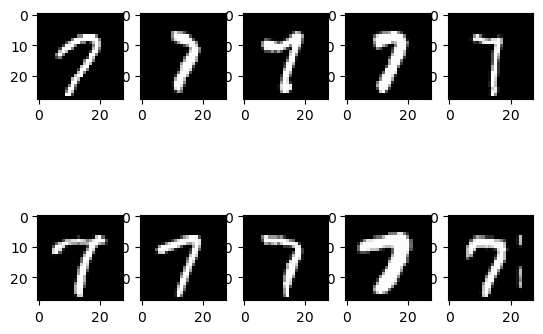

In [85]:
# Find incorrectly classified 7s
wrong_7 = np.where((Y_test == 7) & (Y_pred_sklearn == 9))[0]

# Randomly select 10 images
sample_7 = np.random.choice(wrong_7, 10, replace=False)

# Display images in a 2x5 grid
fig, axes = plt.subplots(2, 5)

for ax, i in zip(axes.flat, sample_7):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")

plt.show()

Here, we selected at random some actual 7s that got misclassified as 9s to examine the visual ambiguity of the hand-writing.

Two insights we can make is that:
1. There are variations in way people write the digit 7s: this could potentially confuse the model, especially if the train set is dominated by one type of writing of 7s, but the test set contains mostly a different way of writing 7s.
2. For each way of writing 7, the writing is actually pretty clear: I would argue that there is no image where we, humans, cannot identify if it is a 7 or a 9. The upper strokes of the 7s are not connected to its vertical stroke at all, so this eliminates how the model can be confused.

We do not have high conviction to reject this hypothesis entirely, but this exploration, at least, let us know this poor visual distinction might not the root cause of the poor performance of the Gaussian models.

#### Final words

Based on the result of our models using Gaussian distribution assumption and some preliminary hypothesis testing practices, we have high conviction that the model performed poorly is attribution to the distribution assumption.

Up next, we will fit the same data using the Bernoulli distribution assumption to see if it actually improves the performance outcomes (very exciting!).

## Assumption: Bernoulli distribution

### I. Hand-coded Bernoulli distribution

#### 1. Model Training

In [92]:
## Binarize
X_train_bin = (X_train < 127).astype(int)
X_test_bin  = (X_test  < 127).astype(int)

## Separate binarized training images by digit
X_train_bin_7 = X_train_bin[Y_train == digit1]
X_train_bin_9 = X_train_bin[Y_train == digit2]

##### a) Calculate priors

In [94]:
prior_7 = prior(Y_train, digit1, digit2)
prior_9 = prior(Y_train, digit2, digit1)

##### b) Laplace smoothing function: Compute Θi,j 

In [96]:
def laplace_theta(X_class):
    return (X_class.sum(axis=0) + 1) / (X_class.shape[0] + 2)

theta_7 = laplace_theta(X_train_bin_7)
theta_9 = laplace_theta(X_train_bin_9)

##### c) Discriminant function g_i(x) for every test image

In [98]:
def bernoulli_discriminant(X, prior, theta):
    return np.log(prior) + X @ np.log(theta) + (1 - X) @ np.log(1 - theta)
    
g_7 = bernoulli_discriminant(X_test_bin, prior_7, theta_7)
g_9 = bernoulli_discriminant(X_test_bin, prior_9, theta_9)

#### 2. Model Testing

In [100]:
# Predict: the class with the larger score wins
pred = np.where(g_9 > g_7, digit2, digit1)

#### 3. Model Evaluating

[[915 113]
 [ 36 973]]
Accuracy: 0.9268532155130094
F1: 0.9288782816229116


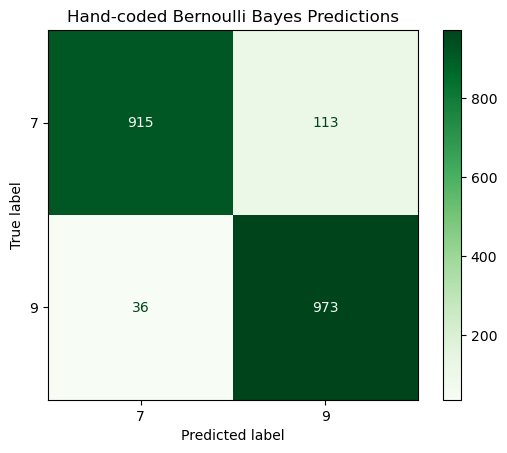

In [102]:
print(confusion_matrix(Y_test, pred, labels=[digit1, digit2]))
print("Accuracy:", accuracy_score(Y_test, pred))
print("F1:", f1_score(Y_test, pred, pos_label=digit2))

ConfusionMatrixDisplay.from_predictions(Y_test, pred, labels=[digit1, digit2], cmap="Greens", values_format="d")
plt.title("Hand-coded Bernoulli Bayes Predictions")
plt.show()

### II. Scikit-Learn Bernoulli distribution

#### 1. Model Training

In [105]:
clf = BernoulliNB(alpha=1.0, binarize=None).fit(X_train_bin, Y_train)

#### 2. Model Testing

In [107]:
pred_sk = clf.predict(X_test_bin)

#### 3. Model Evaluating

[[915 113]
 [ 36 973]]
Accuracy: 0.9268532155130094
F1: 0.9288782816229116


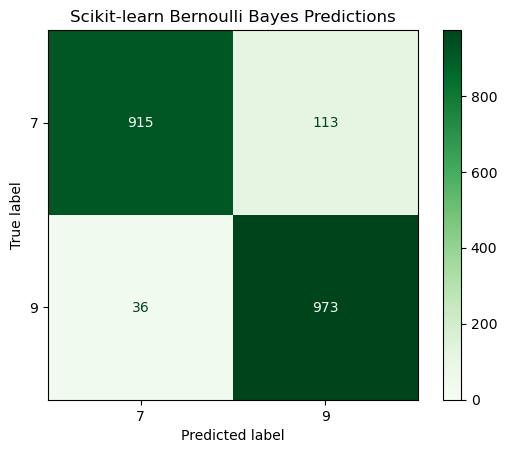

In [109]:
cm_sk = confusion_matrix(Y_test, pred_sk, labels=[digit1, digit2])
print(cm_sk)
print("Accuracy:", accuracy_score(Y_test, pred_sk))
print("F1:", f1_score(Y_test, pred_sk, pos_label=digit2))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_sk, display_labels=[digit1, digit2])
disp.plot(cmap="Greens", values_format="d", im_kw={"vmin": 0})
plt.title("Scikit-learn Bernoulli Bayes Predictions")
plt.show()

### III. Bernoulli Likelihood Analysis
In this version, we assumed a Bernoulli distribution for the likelihood function. Unlike the Gaussian model, which used grayscale values from 0 to 255, the Bernoulli model needs each pixel to be either 0 or 1. Following the threshold suggested in the assignment, we set pixels below 127 to 1 and all other pixels to 0. We then used Laplace smoothing to estimate the probability that each pixel is 1 for each digit. The formula `(count + 1) / (n + 2)` keeps those probabilities from being exactly 0 or 1.

We applied the same approach: fitting the data using hand-coded model and sklearn model. Both models generated relatively the same performance outcomes.

Looking at the confusion matrix, the Bernoulli distribution does a better job overall compared to Gaussian distribution with a much higher accuracy (0.9 > 0.6) and higher F1 score (0.9 > 0.7). This points to the conclusion that Bernoulli is a much better distribution assumption for this dataset. It is consistent with our previous hypothesis that Gaussian is a very poor assumption for the dataset.

Evaluating the two Bernoulli models on their own, they still tend to falsely classified 7s as 9s more than falsely classified 9s as 7s. This means the models still favored predicting 9s compared to 7s. Despite this, precision is still pretty high (0.895), which gives us more conviction to use Bernoulli models on this data for other binary classification problem (with a different pair of digits).

Now this outcome provides support for the aforementioned initial hypothesis (1) (Models performed poorly because of Gaussian assumption), as for next steps beyond this project, we need to examine the hypothesis (3) more closely, which we haven't entirely rejected. The models were still worse at predicting 7s, despite the Bernoulli assumption, could be attributed to the visual ambiguity of 7's writing now.

### IV. Bernoulli with different thresholds

Now we want to test how different thresholds of determining a pixel is 0 or 1 in our binary list. Above, we used 127, which means that pixels with < 127 is classified as 1, and 0 otherwise. Below, we sweep through different thresholds t from 0 to 255 to see how Bernoulli with different thresholds perform.  

#### 1. Model to find the best threshold

Best t by accuracy: 134
Best t by macro F1: 134


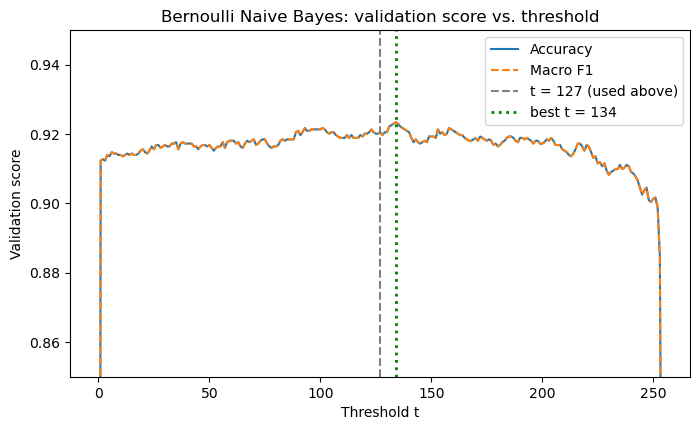

In [163]:
# Split the training set with 80% for training  and 20% for validation (for choosing t) 
# The test set is only used once at the end
rng = np.random.default_rng(0)
val_idx = []
for d in (digit1, digit2):
    idx = rng.permutation(np.where(Y_train == d)[0])
    val_idx.extend(idx[: int(0.2 * len(idx))])

val_mask = np.zeros(len(Y_train), dtype=bool)
val_mask[val_idx] = True

X_tr,  Y_tr  = X_train[~val_mask], Y_train[~val_mask]
X_val, Y_val = X_train[val_mask],  Y_train[val_mask]

thresholds = range(0, 255)
val_acc = []
val_f1 = []

for t in thresholds:
    ## Binarize (1 = pixel below t)
    X_tr_t  = (X_tr  < t).astype(int)
    X_val_t = (X_val < t).astype(int)

    theta_7_t = laplace_theta(X_tr_t[Y_tr == digit1])
    theta_9_t = laplace_theta(X_tr_t[Y_tr == digit2])
    p7 = prior(Y_tr, digit1, digit2)
    p9 = prior(Y_tr, digit2, digit1)

    g7 = bernoulli_discriminant(X_val_t, p7, theta_7_t)
    g9 = bernoulli_discriminant(X_val_t, p9, theta_9_t)

    pred_val = np.where(g9 > g7, digit2, digit1)
    val_acc.append(accuracy_score(Y_val, pred_val))
    val_f1.append(f1_score(Y_val, pred_val, average="macro"))
    
best_t = thresholds[int(np.argmax(val_acc))]
print("Best t by accuracy:", thresholds[int(np.argmax(val_acc))])
print("Best t by macro F1:", thresholds[int(np.argmax(val_f1))])

plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, val_acc, label="Accuracy")
plt.plot(thresholds, val_f1, linestyle="--", label="Macro F1")
plt.axvline(127, color="gray", linestyle="--", label="t = 127 (used above)")
plt.axvline(best_t, color="green", linestyle=":", linewidth=2, label=f"best t = {best_t}")
plt.ylim(0.85, 0.95)                      # zoom in on the plateau
plt.xlabel("Threshold t")
plt.ylabel("Validation score")
plt.title("Bernoulli Naive Bayes: validation score vs. threshold")
plt.legend()
plt.show()

#### 2. Final evaluation with best t = 134

Tuned threshold: 134
Accuracy: 0.928325969563083
Macro F1: 0.9282616372639452


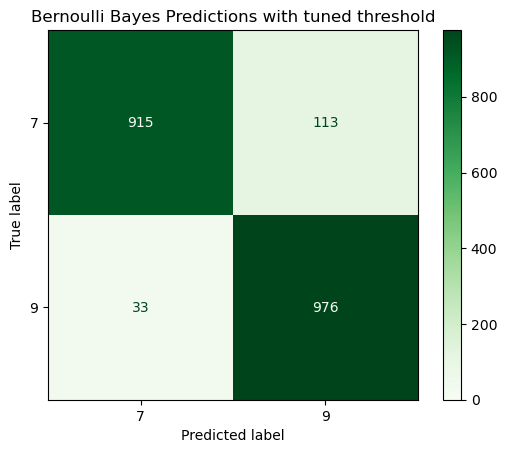

In [175]:
# Retrain on the full training set with the chosen threshold
X_train_t = (X_train < best_t).astype(int)
X_test_t  = (X_test  < best_t).astype(int)

theta_7_f = laplace_theta(X_train_t[Y_train == digit1])
theta_9_f = laplace_theta(X_train_t[Y_train == digit2])
p7_f = prior(Y_train, digit1, digit2)
p9_f = prior(Y_train, digit2, digit1)

g7 = bernoulli_discriminant(X_test_t, p7_f, theta_7_f)
g9 = bernoulli_discriminant(X_test_t, p9_f, theta_9_f)
pred_tuned = np.where(g9 > g7, digit2, digit1)

print("Tuned threshold:", best_t)
print("Accuracy:", accuracy_score(Y_test, pred_tuned))
print("Macro F1:", f1_score(Y_test, pred_tuned, average="macro"))

cm_tuned = confusion_matrix(Y_test, pred_tuned, labels=[digit1, digit2])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tuned, display_labels=[digit1, digit2])
disp.plot(cmap="Greens", values_format="d", im_kw={"vmin": 0})
plt.title("Bernoulli Bayes Predictions with tuned threshold")
plt.show()

#### 3. Result
- As above the tuned threshold does not result in a significant increased in performance for the bernoulli bayes model (the number of 9s that got correctly recognized increased from 973 to 976)

- 
Beyond the scope of this project, as for next steps, we would be interested in testing other hypothesis and trying to explain why the model still performs poorly at predicting 7s.

## Conclusion

All in all, the Bernoulli-distribution model win at classifying between 7s or 9s. This is mainly because the normal distribution assumption for this dataset is inaccurate.

For the Bernoulli models, despite showing a huge improvement from the Gaussian model at predicting 7 (89% of 7s got accurately classified in Bernoulli as opposed to only 31% for Gaussian), they still favor predicting 9, which create more false-classified 7s than 9s. This could be explained by the visual ambiguity of the hand-writing for 7's digit.

To improve the Bernoulli model even further and test that hypothesis, we identify the optimal threshold for the pixel intensity cut-off, which minorly reduce the number of falsely-classified 7s and 9s. As for next steps, we are interested in finding out ways to make the model even better and minimize false classifications.

From this experiment, we learn that in order to fit a high-performing for this dataset, we need to accurately identify the distribution of the pixel intensities on each image of the dataset, and figure out a way to make sure visual ambiguity of the hand-writing does not significantly impact the model's performance outcomes.viewed by the author.

## Citation

Kretchmar, Matt. Bayesian Classifiers. Course lecture notes, n.d.

“Provide guidance on implementing and evaluating Gaussian and Bernoulli Naive Bayes classifiers for MNIST, including Python code, confusion matrices, and hypothesis analysis” prompt. ChatGPT, model GPT-6, OpenAI, 21 Oct. 2026, https://chatgpt.com/

AI Usage Disclosure: ChatGPT (OpenAI, GPT-6) was used to assist with understanding Bayesian classification concepts, reviewing and debugging Python code, interpreting model evaluation metrics, developing hypotheses, and improving the clarity of written analysis. Model implementation, testing, and interpretation of results were conducted and reviewed by the author.